# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
protocol_shape = (512, 512, 300)  # x, y, z
protocol_spacing = (0.5, 0.5, 1.0)
n_voxels = int(np.prod(protocol_shape))
scan_mb = n_voxels * (16 // 8) / 1024**2
extent_mm = tuple(n * d for n, d in zip(protocol_shape, protocol_spacing))
voxel_mm3 = np.prod(protocol_spacing)
# Front view: 512 x 300 rays, each with 512 y samples.
samples_per_frame = (512 * 300) * 512
samples_video = samples_per_frame * 120
samples_video_ert = samples_video * 0.35
print('MB uses 1024² bytes (MiB); extents cover the full voxel cells.')
print(f'{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3')
print(f'samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}')
print('Sample counts use the requested one-sample-per-voxel model, without the display helper’s 2× resampling.')

MB uses 1024² bytes (MiB); extents cover the full voxel cells.
78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400
Sample counts use the requested one-sample-per-voxel model, without the display helper’s 2× resampling.


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

Ignoring spacing would draw the 1.0 mm z dimension like a 0.5 mm in-plane pixel, compressing the head-to-feet extent by a factor of two in coronal and sagittal views. Structures would also have misleading shapes and apparent angles, so a lesion could look flatter and its relation to nearby anatomy could be misread. Distances measured with an assumed isotropic scale would be wrong along z as well.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

Intensity-derived centroid (z,y,x): [27.515 40.478 41.425]; integer slice centre: (np.int64(27), np.int64(40), np.int64(41))


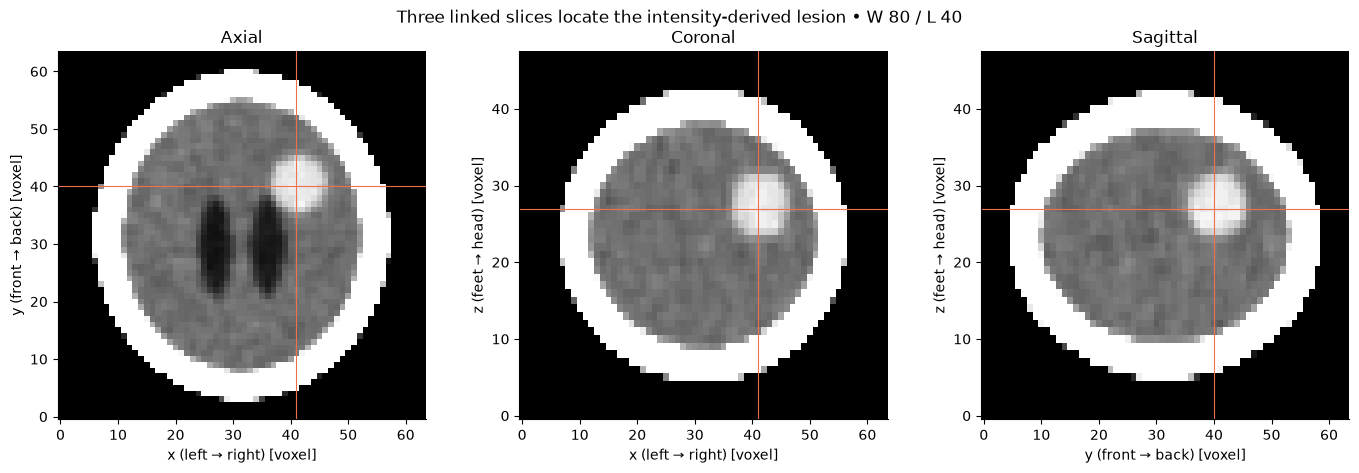

Integer slice-centre error against evaluation labels: 2.92 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

bone = vol > 300
inside = ndimage.binary_fill_holes(bone) & ~bone
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = inside & (vol > 55) & (vol < 90)
components, n_components = ndimage.label(candidates)
sizes = np.bincount(components.ravel())
sizes[0] = 0  # background is never eligible
if n_components == 0:
    raise ValueError('No lesion candidate found using the specified intensity rule.')
lesion = components == sizes.argmax()
centroid_float = np.array(ndimage.center_of_mass(lesion))
cz, cy, cx = centroid_float.astype(int)
print(f'Intensity-derived centroid (z,y,x): {centroid_float.round(3)}; integer slice centre: {(cz, cy, cx)}')

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
planes = [(vol[cz, :, :], 1, cx, cy, 'Axial', 'x (left → right)', 'y (front → back)'),
          (vol[:, cy, :], ASPECT, cx, cz, 'Coronal', 'x (left → right)', 'z (feet → head)'),
          (vol[:, :, cx], ASPECT, cy, cz, 'Sagittal', 'y (front → back)', 'z (feet → head)')]
for ax, (plane, aspect, col, row, title, xlabel, ylabel) in zip(axes, planes):
    ax.imshow(window(plane, 80, 40), cmap='gray', origin='lower', vmin=0, vmax=1, aspect=aspect)
    ax.axvline(col, color='#ef704d', lw=0.8)
    ax.axhline(row, color='#ef704d', lw=0.8)
    ax.set(title=title, xlabel=xlabel + ' [voxel]', ylabel=ylabel + ' [voxel]')
fig.suptitle('Three linked slices locate the intensity-derived lesion • W 80 / L 40')
plt.tight_layout(); plt.show()

# Ground-truth labels enter only here, after the lesion and centre are fixed.
truth_centroid = np.array(ndimage.center_of_mass(labels == 5))
error_mm = np.linalg.norm((np.array([cz, cy, cx]) - truth_centroid) * np.array(SPACING))
print(f'Integer slice-centre error against evaluation labels: {error_mm:.2f} mm')

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

At the skull boundary, one voxel can contain both high-HU bone and lower-HU brain or CSF. Their average can fall in the 55–90 HU candidate range even though the voxel is not tumour, producing a false rim beneath the skull. Eroding the interior mask removes that partial-volume shell before selecting the largest connected lesion, addressing the overlap that an intensity threshold alone cannot distinguish.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold_hu,voxels,volume_ml,dice_evaluation
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


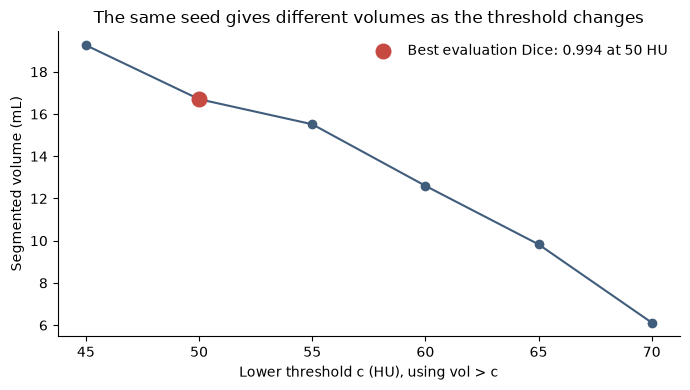

Threshold-sensitivity range to report: 6.12–19.26 mL.
This is a sensitivity range across six thresholds, not a statistical confidence interval.


In [4]:
truth = labels == 5  # evaluation only
rows = []
threshold_regions = {}
for threshold in [45, 50, 55, 60, 65, 70]:
    components, _ = ndimage.label(vol > threshold)
    seed_component = components[cz, cy, cx]
    region = (components == seed_component) if seed_component else np.zeros(vol.shape, dtype=bool)
    threshold_regions[threshold] = region
    count = int(region.sum())
    dice = 2 * np.count_nonzero(region & truth) / (count + np.count_nonzero(truth))
    rows.append({'threshold_hu': threshold, 'voxels': count,
                 'volume_ml': count * VOXEL_MM3 / 1000, 'dice_evaluation': dice})
table = pd.DataFrame(rows)
display(table)
best = table.loc[table.dice_evaluation.idxmax()]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold_hu, table.volume_ml, 'o-', color='#405d7c')
ax.scatter(best.threshold_hu, best.volume_ml, s=110, color='#c64942', zorder=3,
           label=f'Best evaluation Dice: {best.dice_evaluation:.3f} at {best.threshold_hu:g} HU')
ax.set(xlabel='Lower threshold c (HU), using vol > c', ylabel='Segmented volume (mL)',
       title='The same seed gives different volumes as the threshold changes')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print(f'Threshold-sensitivity range to report: {table.volume_ml.min():.2f}–{table.volume_ml.max():.2f} mL.')
print('This is a sensitivity range across six thresholds, not a statistical confidence interval.')

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

Without evaluation labels I would ask the radiologist to choose an intensity range using the CT window, the lesion boundary in all three MPR planes and clinical context, then inspect the seed-connected segmentation for leakage into neighboring tissue. I would justify the threshold by boundary plausibility and stability over nearby thresholds, rather than claiming that the best evaluation Dice is available in practice. I would show volume against threshold alongside overlays of the smallest and largest masks, and report the 6.12–19.26 mL sensitivity range with its thresholds rather than presenting one exact number.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

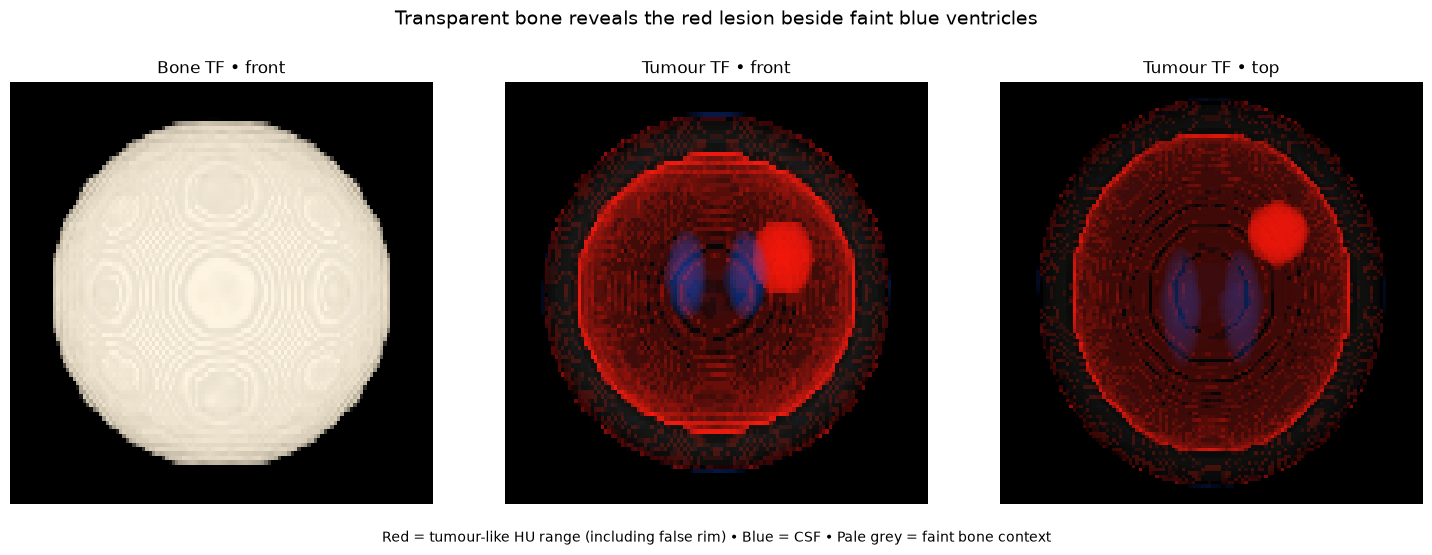

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])
# Narrow transitions avoid coloring the entire soft-tissue range.
# CSF blue is faint per sample; bone opacity remains below 0.01.
tumour_tf = make_tf([
    (-1500, (0, 0, 0), 0), (4, (0, 0, 0), 0),
    (5, (0.1, 0.35, 1), 0.018), (20, (0.1, 0.35, 1), 0.018),
    (21, (0, 0, 0), 0), (54, (0, 0, 0), 0),
    (55, (1, 0.08, 0.03), 0.12), (90, (1, 0.08, 0.03), 0.12),
    (91, (0, 0, 0), 0), (299, (0, 0, 0), 0),
    (300, (0.85, 0.85, 0.8), 0.002), (2000, (0.85, 0.85, 0.8), 0.002)
])
fig, axes = plt.subplots(1, 3, figsize=(15, 5.6))
for ax, tf, axis, title in zip(axes, [bone_tf, tumour_tf, tumour_tf], [1, 1, 0],
                             ['Bone TF • front', 'Tumour TF • front', 'Tumour TF • top']):
    rgb, alpha = render(vol, tf, axis=axis)
    ax.imshow(np.clip(rgb, 0, 1), origin='lower', aspect=ASPECT if axis == 1 else 1)
    ax.set_title(title)
    ax.axis('off')
fig.suptitle('Transparent bone reveals the red lesion beside faint blue ventricles', fontsize=14)
fig.text(0.5, 0.03, 'Red = tumour-like HU range (including false rim) • Blue = CSF • Pale grey = faint bone context',
         ha='center', fontsize=10)
plt.tight_layout(rect=(0, 0.07, 1, 0.94)); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

Overlapping intensities caused by the partial-volume effect give some skull-boundary voxels the same HU as the tumour. A scalar transfer function maps identical HU to identical color and opacity regardless of position, so it cannot remove just that rim. Segmentation followed by an isosurface, or masking the renderer with the intensity-derived connected lesion and interior mask, would isolate the actual candidate while excluding disconnected boundary voxels.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

In this synthetic head CT, the intensity-derived lesion centre is near voxel (x 41, y 40, z 27), toward the right and back of the displayed volume and slightly above its mid-height, with a threshold-dependent volume of 6.12–19.26 mL. I would open the meeting with the linked MPR slices because slicing exposes internal structure without the occlusion of a full skull rendering and keeps the anatomy in its correct physical proportions. The seed-connected segmentation supports measurement, while the threshold plot makes the sensitivity of that measurement visible. The 50 HU threshold has the best overlap with the supplied evaluation labels, but that is retrospective validation rather than a clinical rule for choosing a threshold. The red lesion and blue ventricular context in the 3-D view are useful orientation aids, although overlapping HU and partial-volume voxels also create a false red rim, and appearance depends on accumulated opacity.